## 1、概述

Text Embedding Models：文档嵌入模型，提供将文本编码为向量的能力。即文档向量化。文档写入和用户查询匹配前都会先执行文档嵌入编码，即向量化。

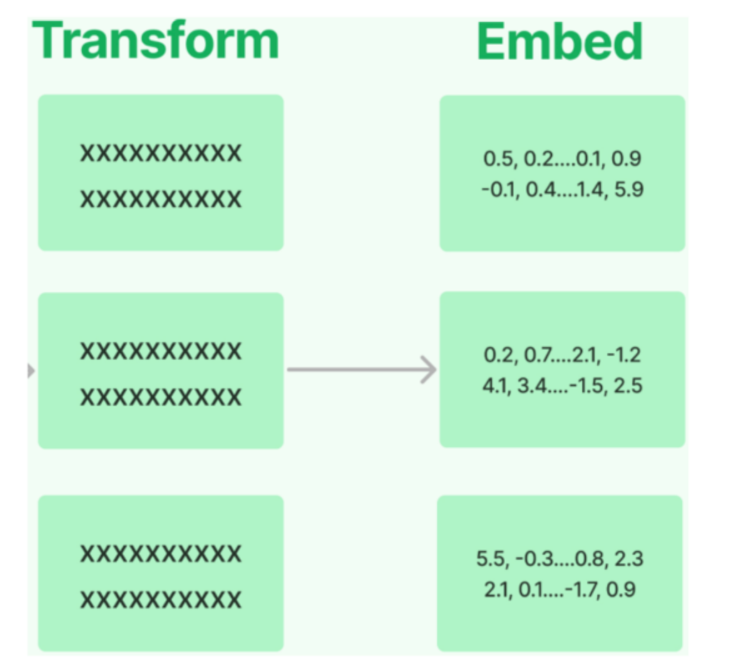

LangChain中针对向量化模型的封装提供了两种接口，一种针对句子的向量化embed_query，一种针对文档的向量化embed_documents。

## 2、句子的向量化

In [1]:
from langchain.embeddings import init_embeddings
import os
from dotenv import load_dotenv

load_dotenv(override=True)

embedding_model = init_embeddings(
    model="qwen3.7-text-embedding-flash",
    provider="openai",
    check_embedding_ctx_length=False,
    api_key=os.getenv("ALIYUN_API_KEY"),
    base_url=os.getenv("ALIYUN_BASE_URL")
)

In [2]:
# 待嵌入的文本句子
text = "What was the name mentioned in the conversation?"

embedded_query = embedding_model.embed_query(text)

print(len(embedded_query))
print(embedded_query[:5])

1024
[-0.006900787353515625, 0.0087890625, 0.0024051666259765625, -0.01253509521484375, 0.00215911865234375]


## 3、文档的向量化

文档的向量化，接收的参数是字符串数组。

In [3]:
# 待嵌入的文本列表
texts = [
    "Hi there!",
    "Oh, hello!",
    "What's your name?",
    "My friends call me World",
    "Hello World!"
]
# 生成嵌入向量
embedded_docs = embedding_model.embed_documents(texts)
for i in range(len(texts)):
    print(f"{texts[i]}:{embedded_docs[i][:3]}",end="\n\n")

Hi there!:[-0.004268646240234375, 0.0322265625, 0.013031005859375]

Oh, hello!:[-0.00386810302734375, 0.05914306640625, 0.050048828125]

What's your name?:[-0.005794525146484375, -0.0034999847412109375, -0.04241943359375]

My friends call me World:[-0.00434112548828125, 0.0214691162109375, 0.0079803466796875]

Hello World!:[-0.0030269622802734375, 0.049713134765625, 0.037445068359375]



In [4]:
from langchain_community.document_loaders import CSVLoader

loader = CSVLoader("../asset/load/02-load.csv", encoding="utf-8")
docs = loader.load_and_split()
texts = [doc.page_content for doc in docs]

embedded_docs = embedding_model.embed_documents(texts)
for i in range(len(texts)):
    print(f"{texts[i]}:{embedded_docs[i][:3]}",end="\n\n")

id: 1
title: Introduction to Python
content: Python is a popular programming language.
author: John Doe:[-0.004459381103515625, -0.036468505859375, -0.036224365234375]

id: 2
title: Data Science Basics
content: Data science involves statistics and machine learning.
author: Jane Smith:[-0.006214141845703125, -0.016632080078125, -0.012115478515625]

id: 3
title: Web Development
content: HTML, CSS and JavaScript are core web technologies.
author: Mike Johnson:[-0.004268646240234375, 0.0418701171875, 0.019622802734375]

id: 4
title: Artificial Intelligence
content: AI is transforming many industries.
author: Sarah Williams:[-0.00786590576171875, -0.060821533203125, 0.01445770263671875]

